# Decoy and Calibration Ablation

This experiment evaluates the effects of decoy design and score calibration on false discovery rate (FDR) control. The analysis includes different decoy-generation strategies and compares FDR estimation before and after score calibration.

This notebook is a guide to using PLM-Caliper in the main experiment and ablation study. It shows the results of the paper's main experiment (the `extended_mkv` decoy) and of the ablation study, and reproduces them step by step.

## 0. Setup

Load the libraries, set the paths, the query set and the target database, and choose the decoy designs to compare in the ablation

In [4]:
import os
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path("..").resolve() 
sys.path.insert(0, f"{REPO_ROOT}/src") 
sys.path.insert(0, f"{REPO_ROOT}/tutorials/utils")
from PLMCaliper import PLMCaliper, DECOY_DESIGNS
from fdr import DEFAULT_Q_LEVELS, FDREvaluator
warnings.filterwarnings("ignore", category=FutureWarning)

In [5]:
# "extended_mkv" is the main-experiment decoy, "shuf" an ablation one
decoy_designs = ["extended_mkv", "shuf"] # add "rev" or "mkv" for more

# score-table name of each search method (BLASTp and DHR scores are post-processed after the search)
search2score_mapping = {"blastp": "blastp_postprocessed", "plm": "plm", "tmvec": "tmvec", "dhr": "dhr_postprocess"}

DATA_DIR = f"{REPO_ROOT}/data"
OUT_DIR = f"{DATA_DIR}/ablation"
FIG_DIR = f"{REPO_ROOT}/results/ablation" 
ENV_FILE = f"{REPO_ROOT}/tutorials/PLM_searching_cmds/.env"
RUN_SEARCH = f"{REPO_ROOT}/tutorials/PLM_searching_cmds/run_search.sh"

QUERY_NAME = "astral" # data/astral.fa
TARGET_NAME = "astral" # searched against itself
MARKOV_ORDER = 2

decoy_tags = {d: DECOY_DESIGNS[d][1].format(k=MARKOV_ORDER)[1:] for d in decoy_designs}
decoy_suffixes = {d: DECOY_DESIGNS[d][0].format(k=MARKOV_ORDER) for d in decoy_designs}
decoy_tags, decoy_suffixes

({'extended_mkv': 'extended_mkv2', 'shuf': 'shuf'},
 {'extended_mkv': '_mkv', 'shuf': '_shuf'})

## 1. Make decoy

Generate one decoy FASTA per design from the query sequences, e.g. `data/astral_shuf.fa` and `data/astral_extended_mkv2.fa`.

In [11]:
# use PLM-caliper to make decoys for FDR control
pc = PLMCaliper()
for design in decoy_designs:
    pc.build_decoy(f"{DATA_DIR}/{QUERY_NAME}.fa", design=design, markov_order=MARKOV_ORDER)

[PLMCaliper] built 15177 'extended_mkv' decoy sequences (suffix = _mkv)
[PLMCaliper] built 15177 'shuf' decoy sequences (suffix = _shuf)


## 2. Search database (Load scores)

Search the real queries and every decoy against the same target database with one retrieval method. If you just want to reproduce the results in this notebook, you only need to run subsection 2-1 (DHR).

**Note:** Protein homolog searching is very time-consuming, so we have saved the search results in advance on [Query Searching Scores](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/raw_searching_data) and [Decoy Searching Scores](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/raw_decoy_searching_score). To save time, this notebook downloads these results directly from Hugging Face and loads them.

Put the downloaded files here (use DHR as an example):

```text
data/
├── result_dhr_postprocess_astral_astral.txt       # real query scores
├── result_dhr_postprocess_astral_mkv2_astral.txt  # mkv decoy scores
└── result_dhr_postprocess_astral_shuf_astral.txt  # shuf decoy scores
```

### 2-1. DHR

Convert the FASTA files to the .tsv format DHR reads, run DHR, then flip its distances into similarity scores.

In [ ]:
searching_method = "dhr"
score_method = search2score_mapping[searching_method] # the name of dhr after postprocess
from fa2tsv import fa2tsv
from process_searching_score import dhr_postprocess

# dhr reads .tsv files instead of FASTA
names = [QUERY_NAME] + [f"{QUERY_NAME}_{decoy_tags[d]}" for d in decoy_designs]
for name in dict.fromkeys(names + [TARGET_NAME]):
    fa2tsv(f"{DATA_DIR}/{name}.fa", f"{DATA_DIR}/{name}.tsv")

# use /PLM_searching_cmds/run_search.sh for dhr; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.tsv"
for name in names:
    query = f"{DATA_DIR}/{name}.tsv"
    result = f"{DATA_DIR}/result_{searching_method}_{name}_{TARGET_NAME}.txt"
    processed = f"{DATA_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(processed) and os.path.getsize(processed) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} already exists")
        continue
    else:
        subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{query}" -t "{target}"'])

    # flip this query's dhr distances into similarity scores
    dhr_postprocess(DATA_DIR, name, TARGET_NAME, [])

[OK] 15177 sequences -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/astral.tsv
[OK] 15177 sequences -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/astral_extended_mkv2.tsv
[OK] 15177 sequences -> /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/astral_shuf.tsv
[skip] For time-saving, dhr-astral already exists
[skip] For time-saving, dhr-astral_extended_mkv2 already exists
[skip] For time-saving, dhr-astral_shuf already exists


### 2-2. PLMsearch

Run PLMsearch on the real queries and the decoys.

In [ ]:
searching_method = "plm" # PLMsearch
score_method = search2score_mapping[searching_method]

# use /PLM_searching_cmds/run_search.sh for plmsearch; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.fa"
for name in [QUERY_NAME] + [f"{QUERY_NAME}_{decoy_tags[d]}" for d in decoy_designs]:
    query = f"{DATA_DIR}/{name}.fa"
    result = f"{DATA_DIR}/result_{searching_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} already exists")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{query}" -t "{target}"'])

[skip] For time-saving, plm-astral already exists
[skip] For time-saving, plm-astral_extended_mkv2 already exists
[skip] For time-saving, plm-astral_shuf already exists


### 2-3. TM-Vec

Run TM-Vec on the real queries and the decoys.

In [ ]:
searching_method = "tmvec"
score_method = search2score_mapping[searching_method]

# use /PLM_searching_cmds/run_search.sh for tmvec; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.fa"
for name in [QUERY_NAME] + [f"{QUERY_NAME}_{decoy_tags[d]}" for d in decoy_designs]:
    query = f"{DATA_DIR}/{name}.fa"
    result = f"{DATA_DIR}/result_{searching_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} already exists")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{query}" -t "{target}"'])

[skip] For time-saving, tmvec-astral already exists
[skip] For time-saving, tmvec-astral_extended_mkv2 already exists
[skip] For time-saving, tmvec-astral_shuf already exists


### 2-4. BLASTp

Run BLASTp, then fill in the query-target pairs BLASTp did not report, so every query has a score for every target.

**Note:** BLASTp scores the best local alignment. An `extended_mkv` decoy keeps the original query sequence as its first half and appends a Markov-generated extension, so BLASTp would simply align that unchanged half and give the decoy the same score as the real query. We therefore cannot use `extended_mkv` with BLASTp, and use the `mkv` decoy here instead.

In [ ]:
searching_method = "blastp"
score_method = search2score_mapping[searching_method] # the name of blastp after postprocess
from process_searching_score import blastp_densify

# BLASTp cannot use extended_mkv (see the note above), so it uses mkv instead
decoy_designs_blastp = ["mkv" if d == "extended_mkv" else d for d in decoy_designs]
decoy_tags.update({d: DECOY_DESIGNS[d][1].format(k=MARKOV_ORDER)[1:] for d in decoy_designs_blastp})
decoy_suffixes.update({d: DECOY_DESIGNS[d][0].format(k=MARKOV_ORDER) for d in decoy_designs_blastp})

# use /PLM_searching_cmds/run_search.sh for blastp; skip searching if score table is already in data/
target = f"{DATA_DIR}/{TARGET_NAME}.fa"
for name in [QUERY_NAME] + [f"{QUERY_NAME}_{decoy_tags[d]}" for d in decoy_designs_blastp]:
    query = f"{DATA_DIR}/{name}.fa"
    result = f"{DATA_DIR}/result_{searching_method}_{name}_{TARGET_NAME}.txt"
    processed = f"{DATA_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(processed) and os.path.getsize(processed) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exists")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && bash "{RUN_SEARCH}" -m {searching_method} -q "{query}" -t "{target}"'])

# BLASTp only reports hits it finds, so we need to fill in the query-target pairs it never reported
out_real = f"{DATA_DIR}/result_blastp_postprocessed_{QUERY_NAME}_{TARGET_NAME}.txt"
for d in decoy_designs_blastp:
    out_decoy = f"{DATA_DIR}/result_blastp_postprocessed_{QUERY_NAME}_{decoy_tags[d]}_{TARGET_NAME}.txt"
    if all(os.path.isfile(f) and os.path.getsize(f) > 0 for f in (out_real, out_decoy)):
        print(f"[skip] For time-saving, blastp_postprocessed-{name} already exists")
        continue
    blastp_densify(
        real=f"{DATA_DIR}/result_blastp_{QUERY_NAME}_{TARGET_NAME}.txt",
        decoy=f"{DATA_DIR}/result_blastp_{QUERY_NAME}_{decoy_tags[d]}_{TARGET_NAME}.txt",
        fasta=f"{DATA_DIR}/{QUERY_NAME}.fa", decoy_suffix=decoy_suffixes[d], eps=1e-4, fallback=0.0,
        out_real=out_real, out_decoy=out_decoy,
    )

[skip] For time-saving, blastp-astral scores already exists
[skip] For time-saving, blastp-astral_mkv2 scores already exists
[skip] For time-saving, blastp-astral_shuf scores already exists
[skip] For time-saving, blastp_postprocessed-astral_shuf already exists
[skip] For time-saving, blastp_postprocessed-astral_shuf already exists


## 3. Run PLM-Caliper

Calibrate each decoy design's scores against the real scores with PLM-Caliper (tau = 0.25, as in the paper), and attach the homology labels to the noise-matched target table. In this notebook, we only show the procedures for DHR.

**Note:** To save time, we have saved the calibrated scores in advance on [Calibrated Decoy Scores](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/calibrated_decoy_score) and [Noisy Target Scores](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/noisy_target_score). This notebook downloads these results directly from Hugging Face and loads them.

Put the downloaded files here:

```text
data/
└── ablation/
    └── dhr_postprocess_astral_extended_mkv2_AdaptiveBell_astral/
        ├── calibrated_decoy.tsv   # from calibrated_decoy_score in HF
        └── target_noisy.tsv       # from noisy_target_score/ in HF
```

In [6]:
# set parameters
searching_method = "dhr"
score_method = search2score_mapping[searching_method]
TAU = 0.25
NUM_POINTS = 1000
Q_LEVELS = [round(0.1 * i, 1) for i in range(1, 10)]

for design in (decoy_designs_blastp if searching_method == "blastp" else decoy_designs):
    # loading data
    real = f"{DATA_DIR}/result_{score_method}_{QUERY_NAME}_{TARGET_NAME}.txt"
    decoy = f"{DATA_DIR}/result_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_{TARGET_NAME}.txt"
    out_dir = f"{OUT_DIR}/{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}"
    if all(os.path.isfile(f"{out_dir}/{f}") and os.path.getsize(f"{out_dir}/{f}") > 0
           for f in ("calibrated_decoy.tsv", "target_noisy.tsv")):
        print(f"[skip] For time-saving, calibrated_decoy.tsv + target_noisy.tsv ({searching_method}-{decoy_tags[design]}) already exist")
        continue
    df_real = pd.read_csv(real, sep="\t").dropna(subset=["score"])
    df_decoy = pd.read_csv(decoy, sep="\t").dropna(subset=["score"])

    # run PLM-Caliper
    pc = PLMCaliper(tau=TAU, num_points=NUM_POINTS)
    result = pc.plmcaliper(df_real, df_decoy, sorted(Q_LEVELS))

    # save intermediate results
    os.makedirs(out_dir, exist_ok=True)
    noisy_target = result.noisy_target.merge(df_real[["qid", "tid", "homo_type"]], on=["qid", "tid"], how="left")
    result.calibrated_decoy.to_csv(f"{out_dir}/calibrated_decoy.tsv", sep="\t", index=False)
    noisy_target.to_csv(f"{out_dir}/target_noisy.tsv", sep="\t", index=False)
    result.cutoffs.to_csv(f"{out_dir}/cutoffs.tsv", sep="\t", index=False)
    print(f"[OK] target_noisy.tsv + calibrated_decoy.tsv + cutoffs.tsv -> {out_dir}")

[skip] For time-saving, calibrated_decoy.tsv + target_noisy.tsv (dhr-extended_mkv2) already exist
[skip] For time-saving, calibrated_decoy.tsv + target_noisy.tsv (dhr-shuf) already exist


## 4. Compute real FDR, Power, and Accuracy

For each target FDR level, take every query's PLM-Caliper cutoff and evaluate it against the homology labels; we will compare real FDR, power, and accuracy.

In [19]:
CSV_DIR = f"{OUT_DIR}/plot_data"
EVAL_Q_LEVELS = sorted(round(float(q), 2) for q in DEFAULT_Q_LEVELS)    # 0.05, 0.10, ..., 0.95

def evaluation(calibrated_decoy, noisy_target, q_levels, decoy_suffix):
    """compute real FDR, power, and accuracy with real homolog labels"""
    agg = FDREvaluator(decoy_suffix, q_levels).evaluate(noisy_target, calibrated_decoy, n_jobs=4)
    real_fdr, power, accuracy = (
        pd.DataFrame([{"q": float(q), col: float(v)} for q, vals in zip(agg["q_levels"], agg[key]) for v in vals],
                     columns=["q", col])
        for key, col in (("all_real_fdps_per_q", "real_fdp"), ("all_powers_per_q", "power"),
                         ("all_accuracy_per_q", "accuracy")))
    summary = pd.DataFrame({"q": agg["q_levels"], "mean_real_fdr": agg["mean_real_fdr"],
                            "mean_power": agg["mean_power"], "mean_accuracy": agg["mean_accuracy"],
                            "valid_count": agg["valid_count"]})
    summary["total_curves"] = agg["total_curves"]
    summary["n_unique_qids"] = agg["n_unique_qids"]
    return real_fdr, power, accuracy, summary

os.makedirs(CSV_DIR, exist_ok=True)
for design in (decoy_designs_blastp if searching_method == "blastp" else decoy_designs):
    real_fdr, power, accuracy, summary = evaluation(
        f"{OUT_DIR}/{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}/calibrated_decoy.tsv",
        f"{OUT_DIR}/{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}/target_noisy.tsv",
        EVAL_Q_LEVELS, decoy_suffixes[design])
    summary.to_csv(f"{CSV_DIR}/fdr_curve_agg_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}.csv", index=False)
    real_fdr.to_csv(f"{CSV_DIR}/fdr_boxpoints_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}.csv", index=False)
    power.to_csv(f"{CSV_DIR}/power_boxpoints_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}.csv", index=False)
    accuracy.to_csv(f"{CSV_DIR}/accuracy_boxpoints_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}.csv", index=False)
    print(f"[OK] Real FDR, power, and accuracy data are saved to {CSV_DIR}")

  streaming the pair table (19.9 GB)


  -> Computing TDA curves: 15177query [44:30,  5.68query/s]


[OK] Real FDR, power, and accuracy data are saved to /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/ablation/plot_data
  streaming the pair table (20.1 GB)


  -> Computing TDA curves: 15177query [41:11,  6.14query/s]


[OK] Real FDR, power, and accuracy data are saved to /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/ablation/plot_data


## 5. Plot

After calibration for the decoy scores, plot the real FDR, power, accuracy and number of queries with a valid cutoff at each target FDR level.


>>> dhr_postprocess / extended_mkv2


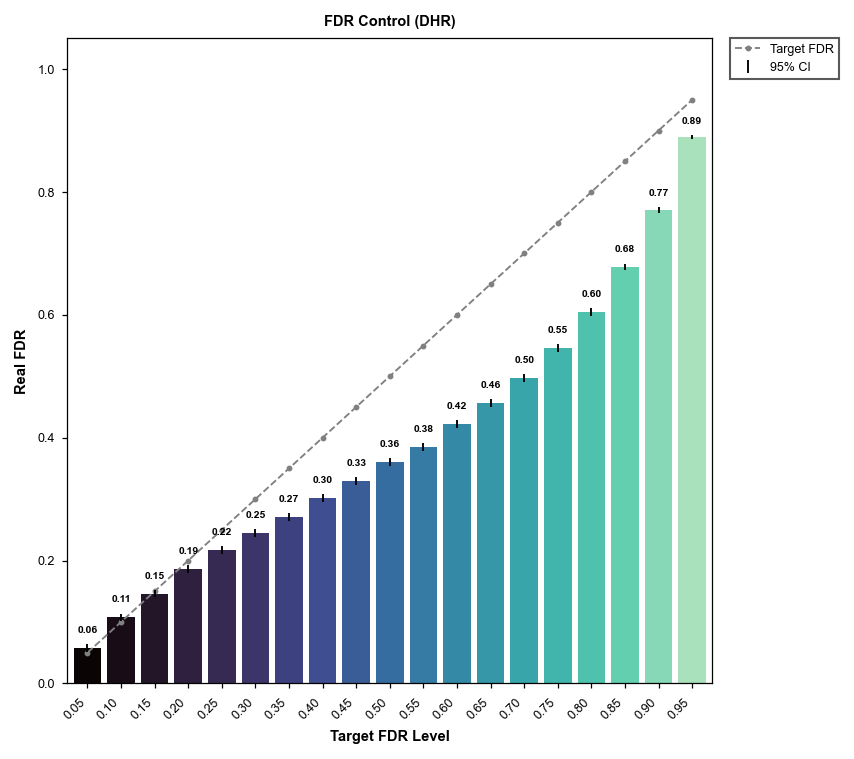

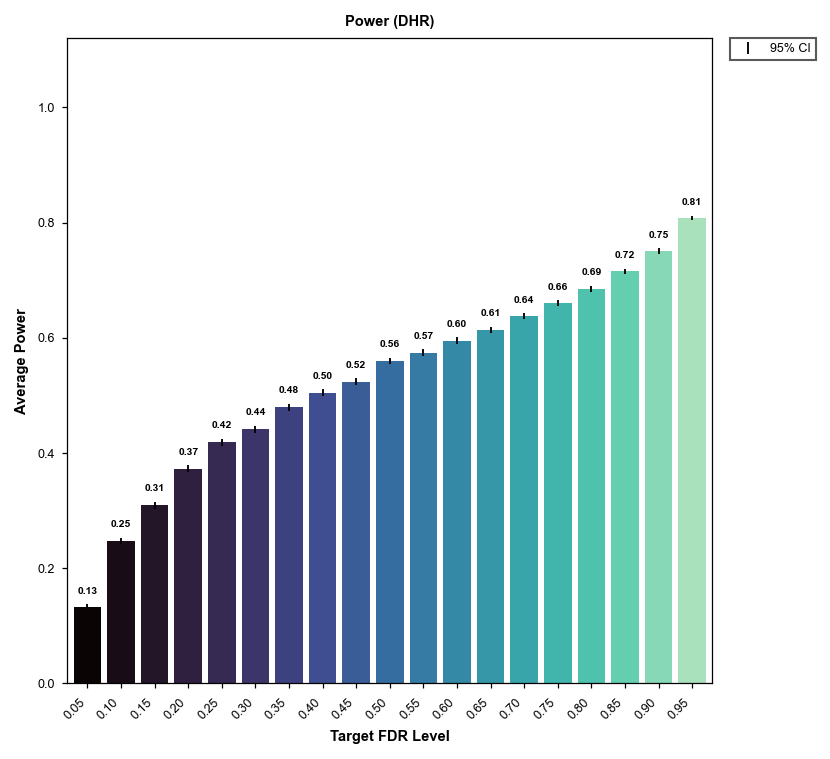

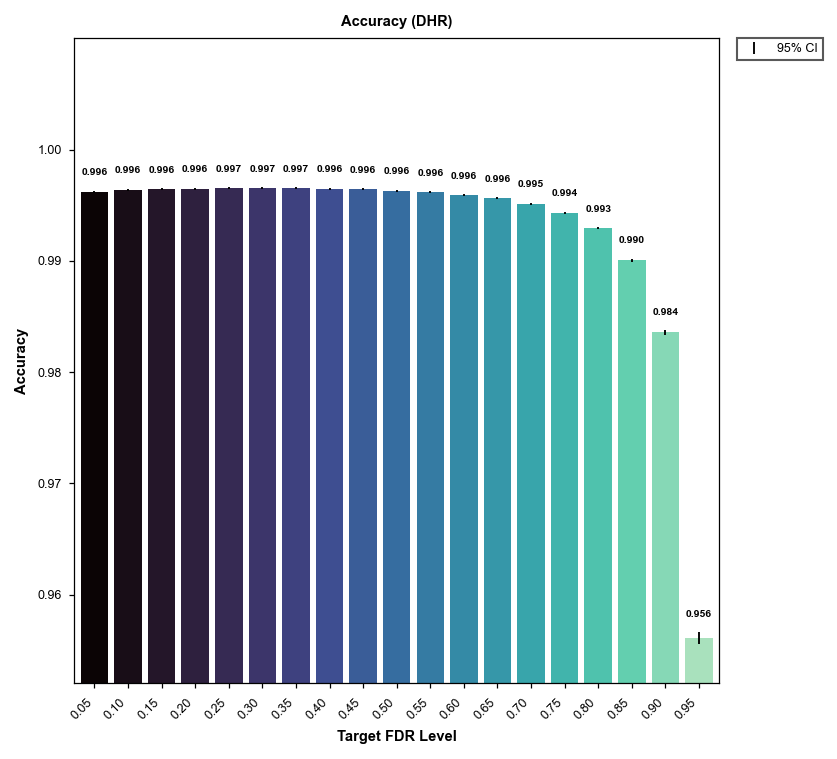

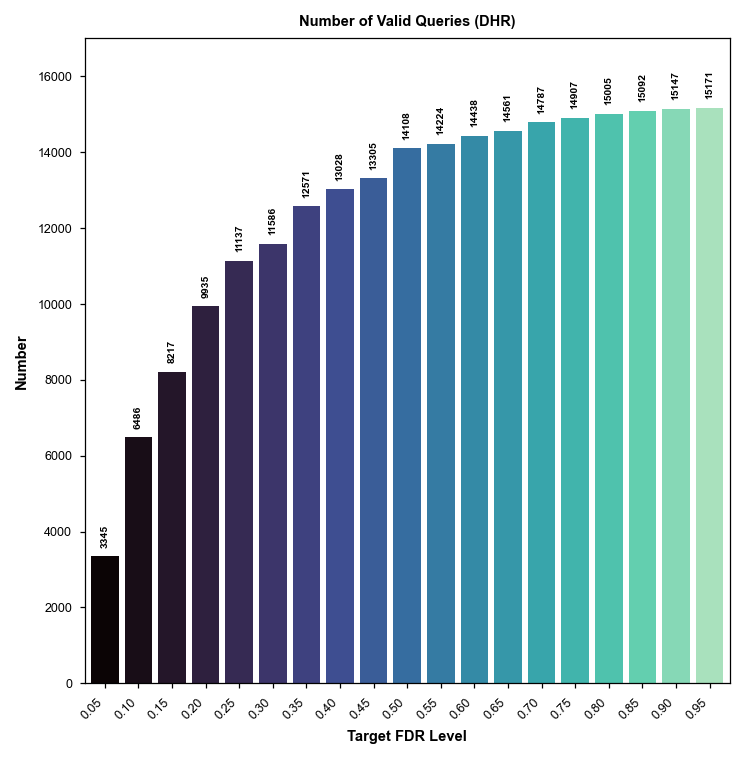


>>> dhr_postprocess / shuf


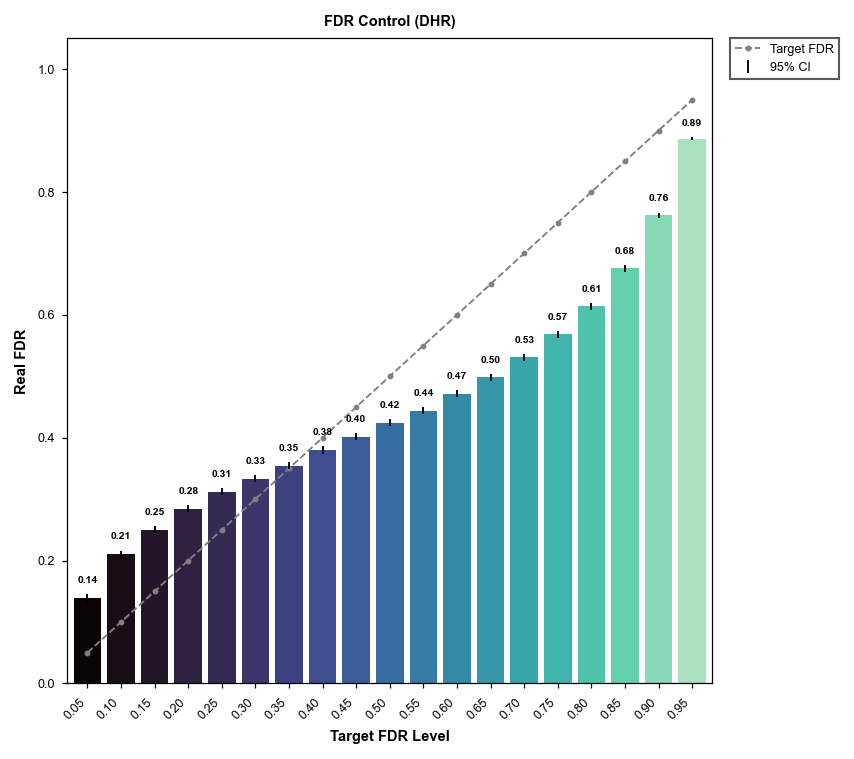

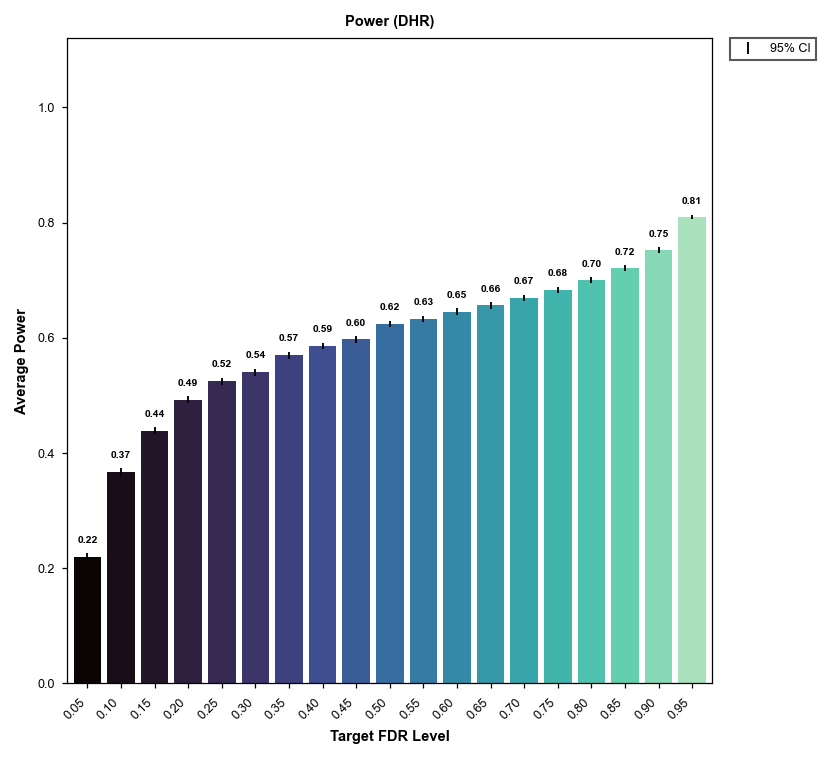

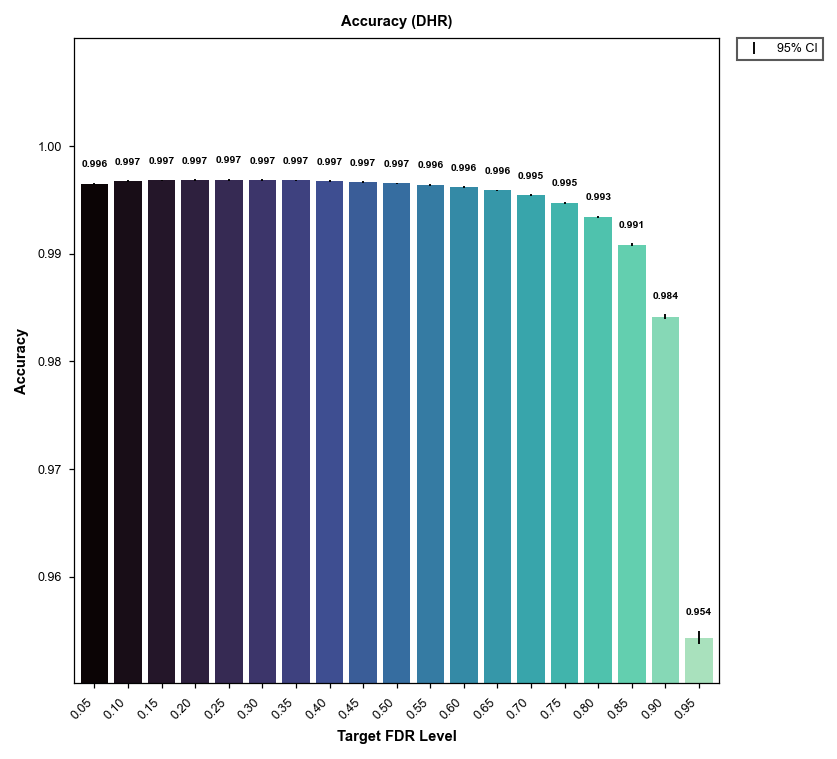

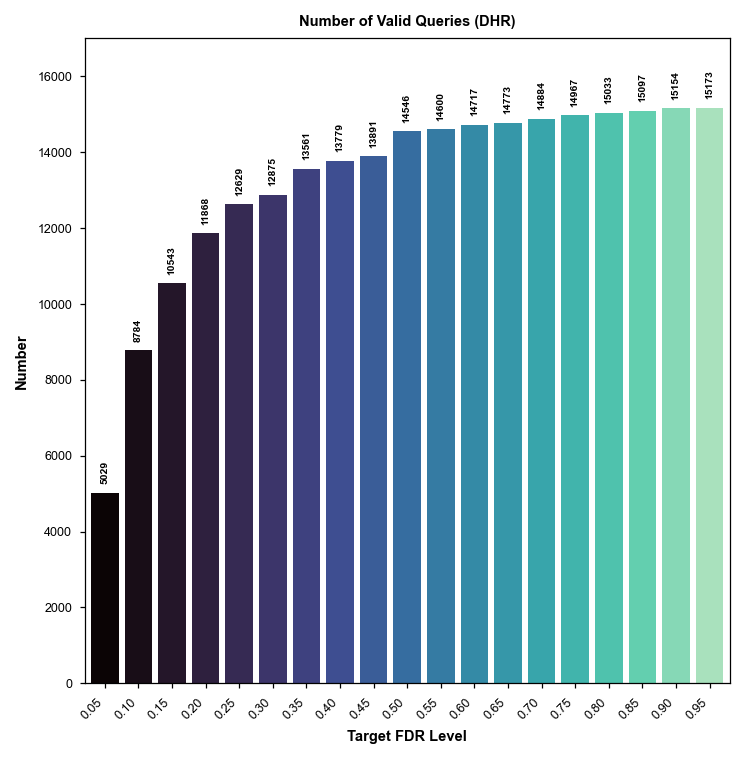

In [22]:
# set plotting pattern
matplotlib.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "Nimbus Sans", "Liberation Sans", "TeX Gyre Heros", "DejaVu Sans"]
                       + list(matplotlib.rcParams["font.sans-serif"]),
    "axes.unicode_minus": False, "font.size": 6, "axes.labelsize": 7, "axes.titlesize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "lines.linewidth": 0.9, "lines.markersize": 3.0, "grid.linewidth": 0.4,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "savefig.dpi": 400, "figure.dpi": 150, "legend.frameon": True, "legend.framealpha": 1.0,
})
CMAP = mcolors.LinearSegmentedColormap.from_list(
    "fdr_mako", ["#0b0405", "#28192e", "#3b2f5f", "#3f4a8f", "#366ca0", "#348da7", "#39acac", "#59ccad", "#a9e1bd"])
SEARCH_LABEL = {"plm": "PLMsearch", "tmvec": "TMvec", "dhr_postprocess": "DHR", "blastp_postprocessed": "BLASTp"}

# define utils for plotting
def _bar_panel(q_levels, values, ci=None, fmt="{:.2f}", rotation=0, gap=None):
    fig_w, fig_h = 5.92, 5.25
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([0.6 / fig_w, 0.6 / fig_h, 4.3 / fig_w, 4.3 / fig_h])
    ax.set_box_aspect(1)

    values = np.asarray(values, dtype=float)
    x = np.arange(len(q_levels))
    ax.bar(x, values, width=0.82, color=[CMAP(i / (len(x) - 1)) for i in range(len(x))], edgecolor="none", zorder=2)
    tops = values
    if ci is not None:
        ax.errorbar(x, values, yerr=ci, fmt="none", ecolor="black", elinewidth=0.9, capsize=0, zorder=4,
                    label="95% CI")
        tops = values + ci
    top = float(np.nanmax(tops))
    g = gap if gap is not None else 0.015 * max(top, 1.0)
    for xi, v, t in zip(x, values, tops):
        if not np.isnan(v):
            ax.text(xi, t + g, fmt.format(v), ha="center", va="bottom", rotation=rotation, fontsize=5,
                    fontweight="bold", color="black", zorder=5)

    ax.set_xlim(-0.6, len(q_levels) - 0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{q:.2f}" for q in q_levels], rotation=45, ha="right")
    ax.set_axisbelow(True)
    return fig, ax, top

def _finish_plot(fig, ax, ylabel, title, out):
    ax.set_xlabel("Target FDR Level", fontsize=7, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=7, fontweight="bold")
    ax.set_title(title, fontsize=7, fontweight="bold")
    pos = ax.get_position()
    if ax.get_legend_handles_labels()[0]:
        legend = ax.legend(fontsize=6, loc="upper left", bbox_to_anchor=(pos.x1 + 0.02, pos.y1),
                           bbox_transform=fig.transFigure, frameon=True, fancybox=False, edgecolor="0.35",
                           facecolor="white", ncol=1, borderaxespad=0.0)
        fig.canvas.draw()
        pos = ax.get_position()
        w, h = fig.get_size_inches()
        left, bottom, width, height = pos.x0 * w, pos.y0 * h, pos.width * w, pos.height * h
        new_w = max(left + width, legend.get_window_extent(fig.canvas.get_renderer()).x1 / fig.dpi) + 0.18
        if new_w > w + 1e-6:
            fig.set_size_inches(new_w, h, forward=True)
            ax.set_position([left / new_w, bottom / h, width / new_w, height / h])
            legend.set_bbox_to_anchor(((left + width + 0.12) / new_w, ax.get_position().y1),
                                      transform=fig.transFigure)
    # plt.savefig(out, format="pdf")
    plt.show()
    # print(f"[OK] {out}")


# define fdr, power, accuracy, and valid_count plotting functions
def plot_fdr(real_fdr, q, label, out):
    g = real_fdr.groupby("q")["real_fdp"]
    m, ci = g.mean().to_numpy(), 1.96 * g.sem().to_numpy()

    fig, ax, top = _bar_panel(q, m, ci)
    ax.plot(np.arange(len(q)), q, linestyle="--", color="gray", linewidth=0.9, marker="o", markersize=3.0 * 0.6,
            zorder=3, label="Target FDR")
    ax.set_ylim(0, max(top * 1.12, 1.05))
    _finish_plot(fig, ax, "Real FDR", f"FDR Control ({label})", out)


def plot_power(power, q, label, out):
    g = power.groupby("q")["power"]
    m, ci = g.mean().to_numpy(), 1.96 * g.sem().to_numpy()

    fig, ax, _ = _bar_panel(q, m, ci)
    ax.set_ylim(0, 1.12)
    _finish_plot(fig, ax, "Average Power", f"Power ({label})", out)


def plot_accuracy(accuracy, q, label, out):
    g = accuracy.groupby("q")["accuracy"]
    m, ci = g.mean().to_numpy(), 1.96 * g.sem().to_numpy()

    top_max, bot = float(np.nanmax(m + ci)), float(np.nanmin(m))
    rng = max(top_max - bot, 0.02)
    fig, ax, _ = _bar_panel(q, m, ci, fmt="{:.3f}", gap=0.03 * rng)
    lo = max(0.0, bot - 0.10 * rng)
    ax.set_ylim(lo, max(top_max, 1.0) + 0.02)
    yt = ax.get_yticks()
    ax.set_ylim(lo, 1.0 + float(yt[1] - yt[0]))
    ax.set_yticks([t for t in ax.get_yticks() if lo - 1e-9 <= t <= 1.0 + 1e-9])
    _finish_plot(fig, ax, "Accuracy", f"Accuracy ({label})", out)

def plot_valid_count(summary, label, out):
    fig, ax, _ = _bar_panel(summary["q"].to_numpy(), summary["valid_count"].to_numpy(), fmt="{:.0f}", rotation=90)
    ax.set_ylim(0, int(summary["total_curves"].iloc[0]) * 1.12)
    _finish_plot(fig, ax, "Number", f"Number of Valid Queries ({label})", out)

# plot
os.makedirs(FIG_DIR, exist_ok=True)
for design in (decoy_designs_blastp if searching_method == "blastp" else decoy_designs):
    tag = f"{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell_{TARGET_NAME}"
    out = f"{FIG_DIR}/{score_method}_{QUERY_NAME}_{decoy_tags[design]}_AdaptiveBell"
    summary, real_fdr, power, accuracy = (pd.read_csv(f"{CSV_DIR}/{stem}_{tag}.csv") for stem in
                                          ("fdr_curve_agg", "fdr_boxpoints", "power_boxpoints", "accuracy_boxpoints"))
    q, label = summary["q"].to_numpy(), SEARCH_LABEL[score_method]
    print(f"\n>>> {score_method} / {decoy_tags[design]}")

    plot_fdr(real_fdr, q, label, f"{out}_FDR_boxplots.pdf")
    plot_power(power, q, label, f"{out}_Power.pdf")
    plot_accuracy(accuracy, q, label, f"{out}_Accuracy.pdf")
    plot_valid_count(summary, label, f"{out}_ValidCount.pdf")

## 6. Comparison without calibration

Before calibration for the decoy scores, plot the real FDR, power, accuracy and number of queries with a valid cutoff at each target FDR level.

In [25]:
# compute plotting data for without calibration setting
for design in (decoy_designs_blastp if searching_method == "blastp" else decoy_designs):
    real_fdr, power, accuracy, summary = evaluation(
        f"{DATA_DIR}/result_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_{TARGET_NAME}.txt",
        f"{DATA_DIR}/result_{score_method}_{QUERY_NAME}_{TARGET_NAME}.txt",
        EVAL_Q_LEVELS, decoy_suffixes[design])
    summary.to_csv(f"{CSV_DIR}/fdr_curve_agg_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_nocalib_{TARGET_NAME}.csv", index=False)
    real_fdr.to_csv(f"{CSV_DIR}/fdr_boxpoints_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_nocalib_{TARGET_NAME}.csv", index=False)
    power.to_csv(f"{CSV_DIR}/power_boxpoints_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_nocalib_{TARGET_NAME}.csv", index=False)
    accuracy.to_csv(f"{CSV_DIR}/accuracy_boxpoints_{score_method}_{QUERY_NAME}_{decoy_tags[design]}_nocalib_{TARGET_NAME}.csv", index=False)
    print(f"[OK] Real FDR, power, and accuracy data without calibration are saved to {CSV_DIR}")

  streaming the pair table (19.0 GB)


  -> Computing TDA curves: 15177query [36:51,  6.86query/s]


[OK] Real FDR, power, and accuracy data without calibration are saved to /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/ablation/plot_data
  streaming the pair table (19.2 GB)


  -> Computing TDA curves: 15177query [36:45,  6.88query/s]


[OK] Real FDR, power, and accuracy data without calibration are saved to /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/ablation/plot_data



>>> dhr_postprocess / extended_mkv2


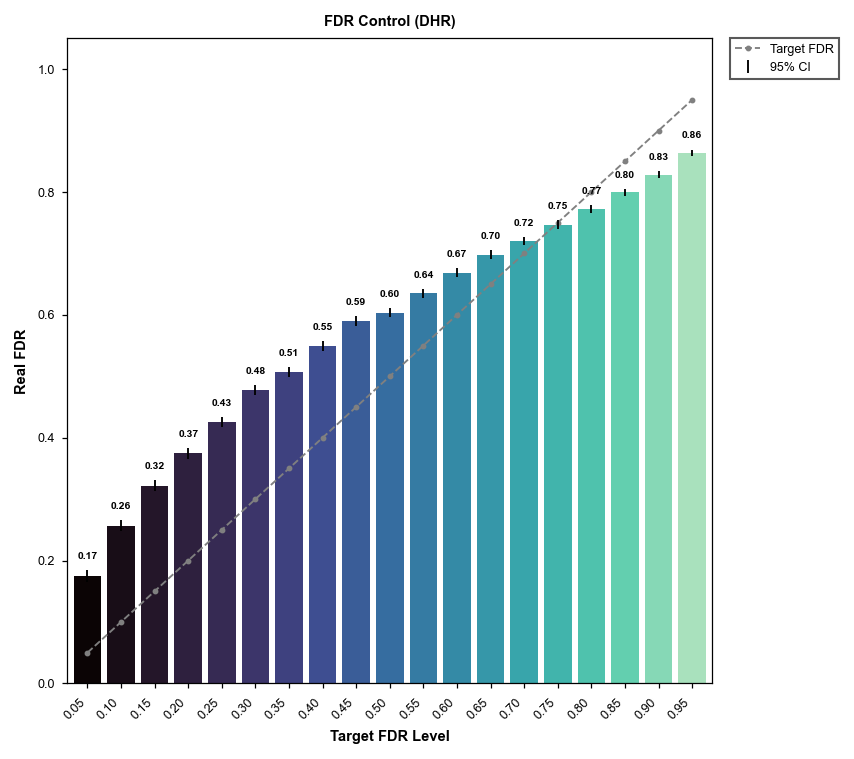

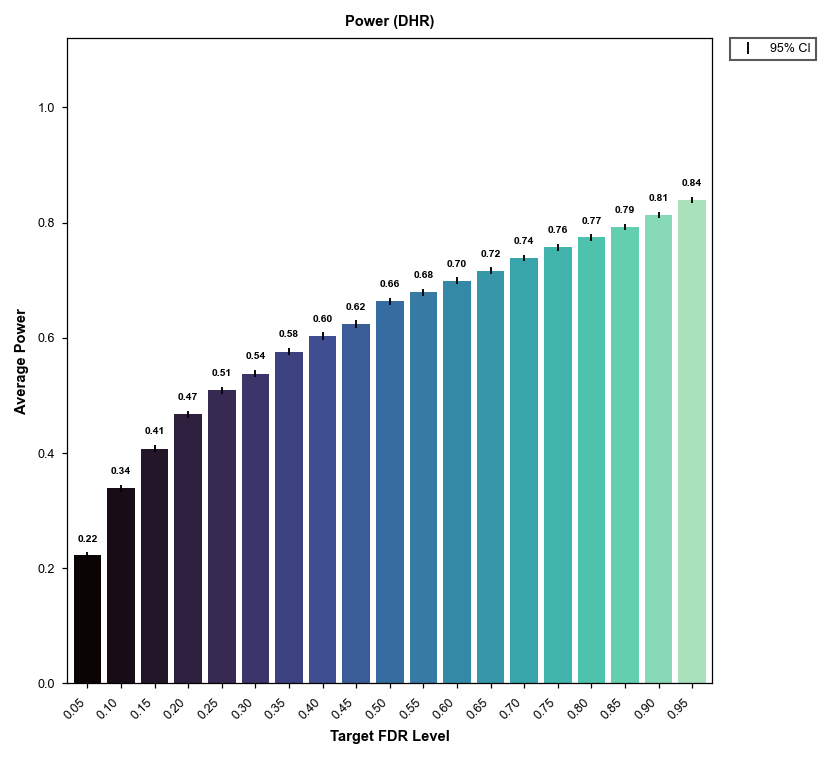

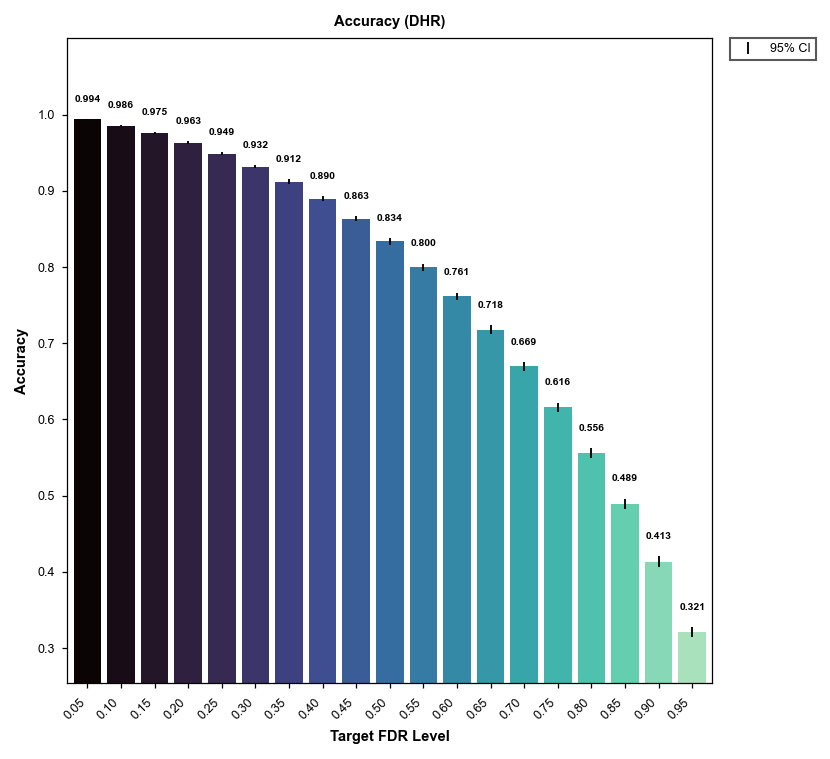

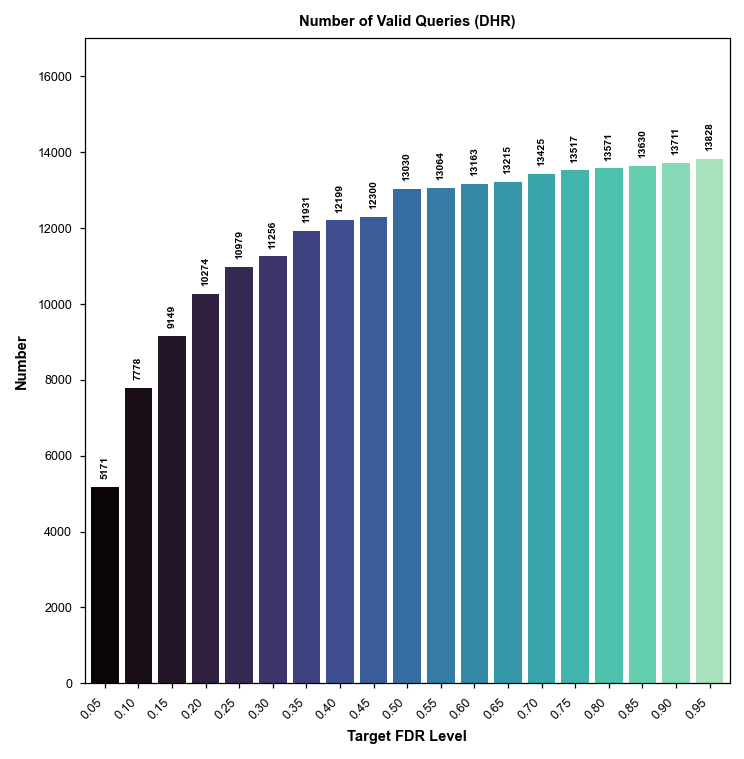


>>> dhr_postprocess / shuf


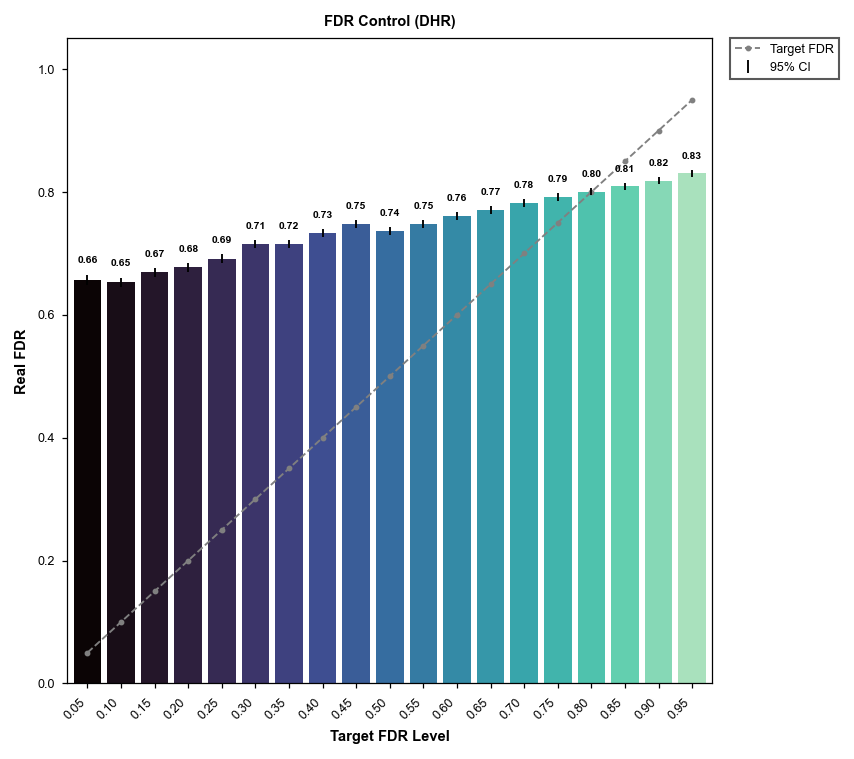

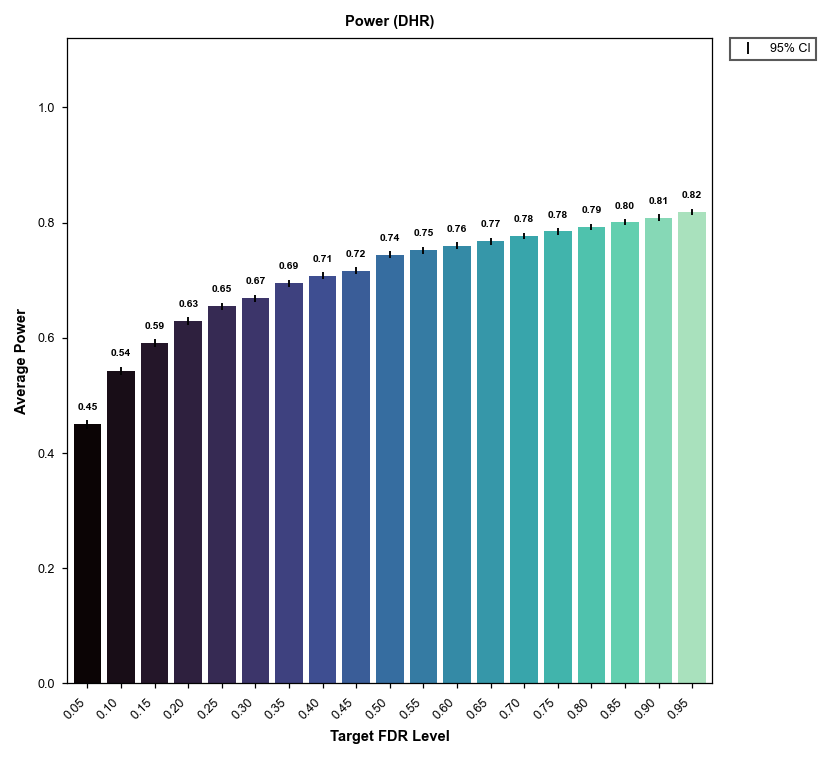

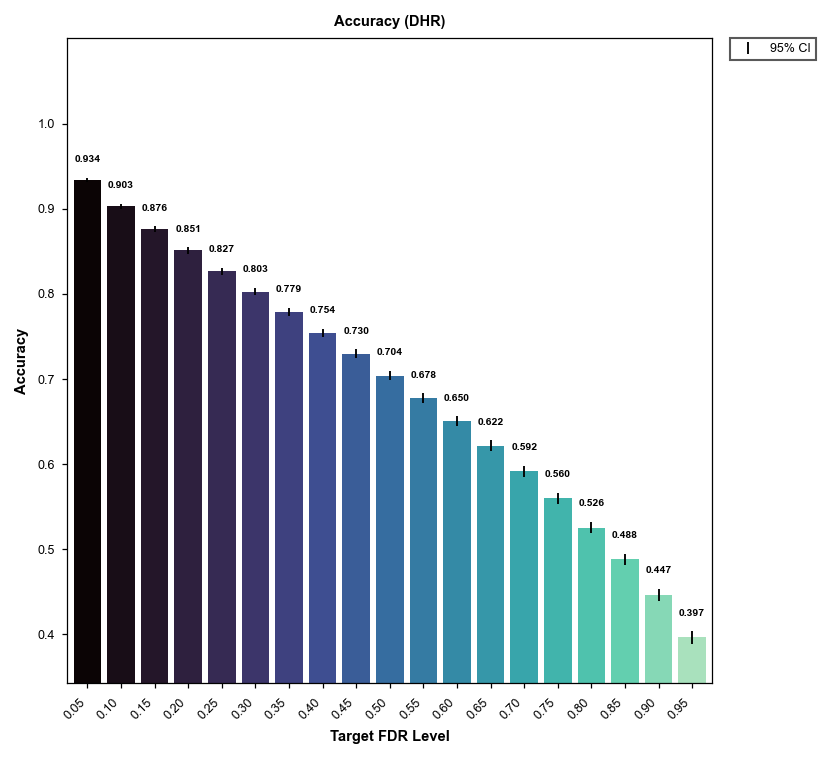

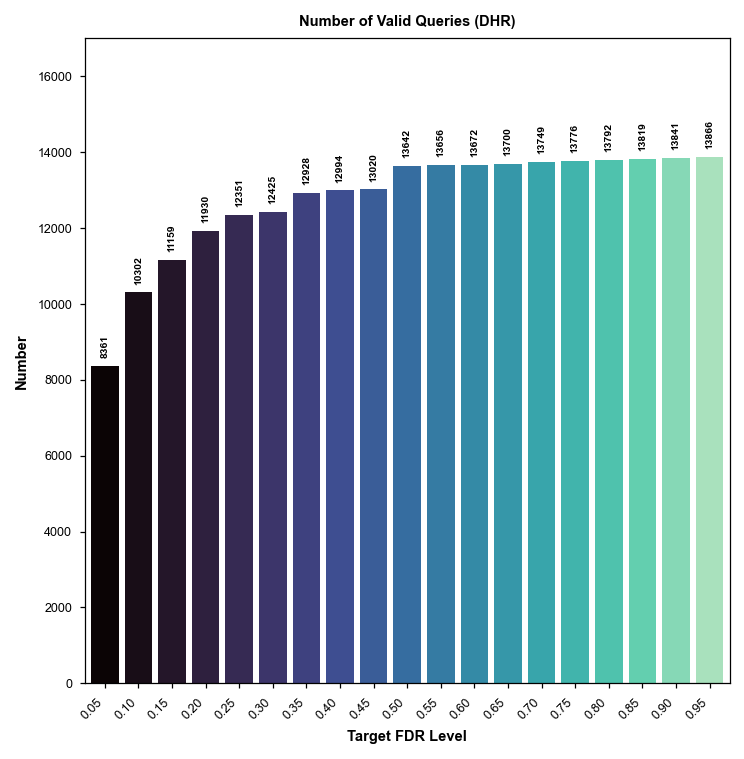

In [26]:
# plot
for design in (decoy_designs_blastp if searching_method == "blastp" else decoy_designs):
    tag = f"{score_method}_{QUERY_NAME}_{decoy_tags[design]}_nocalib_{TARGET_NAME}"
    out = f"{FIG_DIR}/{score_method}_{QUERY_NAME}_{decoy_tags[design]}_nocalib"
    summary, real_fdr, power, accuracy = (pd.read_csv(f"{CSV_DIR}/{stem}_{tag}.csv") for stem in
                                          ("fdr_curve_agg", "fdr_boxpoints", "power_boxpoints", "accuracy_boxpoints"))
    q, label = summary["q"].to_numpy(), SEARCH_LABEL[score_method]
    print(f"\n>>> {score_method} / {decoy_tags[design]}")

    plot_fdr(real_fdr, q, label, f"{out}_FDR_boxplots.pdf")
    plot_power(power, q, label, f"{out}_Power.pdf")
    plot_accuracy(accuracy, q, label, f"{out}_Accuracy.pdf")
    plot_valid_count(summary, label, f"{out}_ValidCount.pdf")